In [12]:
import numpy as np
import mitsuba as mi
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

from sionna.rt import load_scene, Transmitter, PlanarArray, RadioMapSolver

In [13]:
scene = load_scene()

scene.tx_array = PlanarArray(num_rows=1, 
                             num_cols=1,
                             pattern="iso", 
                             polarization="V")
scene.rx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             pattern="iso", 
                             polarization="V")

scene.remove("tx0")
scene.remove("tx1")

POS_A = (150.0, -100.0, 20.0)   # Position before movement

tx = Transmitter("tx0", 
                 position=mi.Point3f(*POS_A), 
                 orientation=mi.Point3f(np.pi*5/6, 0, 0))
scene.add(tx)

rm_solver = RadioMapSolver()
rm = rm_solver(scene,
                   max_depth=5,
                   samples_per_tx=10**7,
                   cell_size=mi.Point2f(5, 5),
                   center=mi.Point3f(0, 0, 0),
                   size=mi.Point2f(400, 400),
                   orientation=mi.Point3f(0, 0, 0))

pg_a = rm.path_gain.numpy()[0]   #linear Path gain of position A

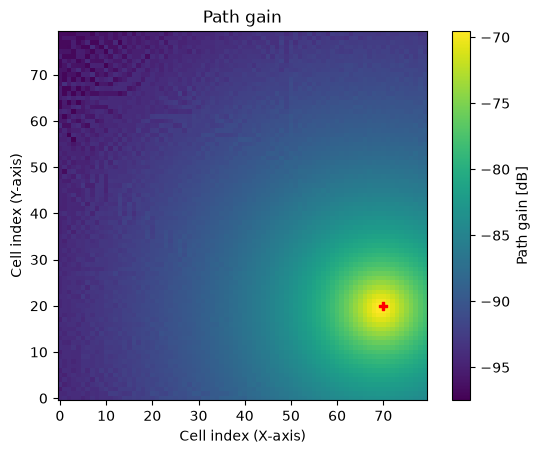

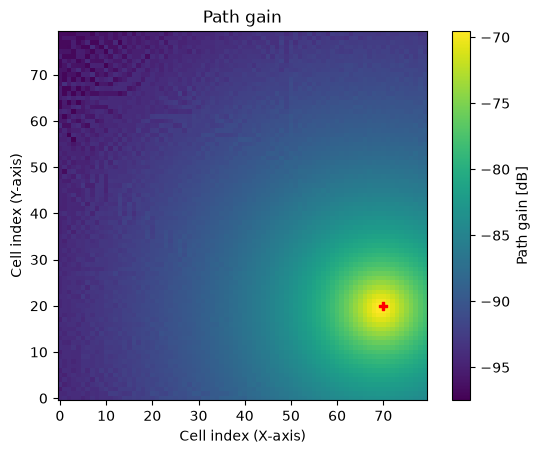

In [ ]:
rm.show(metric = "path_gain")

tx position: [[-150, -100, 20]]


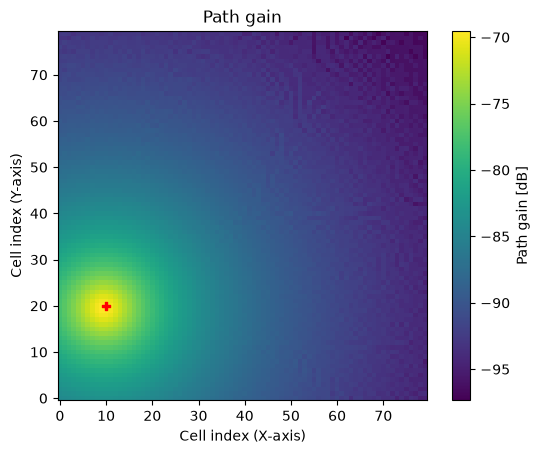

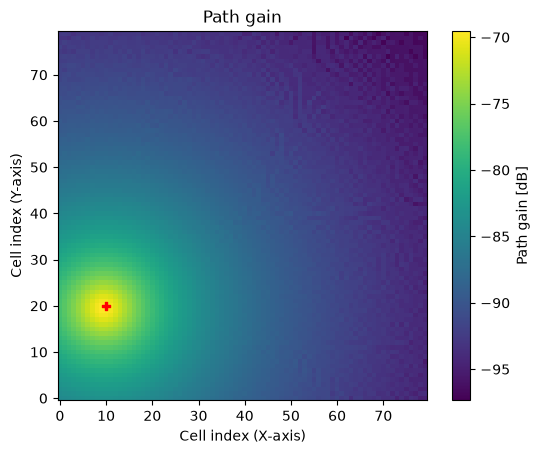

In [15]:
scene.remove("tx1")

POS_B = (-150.0, -100.0, 20.0)   # position after movement

tx.position = mi.Point3f(*POS_B)

rm = rm_solver(scene,
               max_depth=5,
               samples_per_tx=10**7,
               cell_size=mi.Point2f(5, 5),
               center=mi.Point3f(0, 0, 0),
               size=mi.Point2f(400, 400),
               orientation=mi.Point3f(0, 0, 0))

pg_b = rm.path_gain.numpy()[0]   #linear path gain of position B

print("tx position:", tx.position)
rm.show(metric="path_gain")

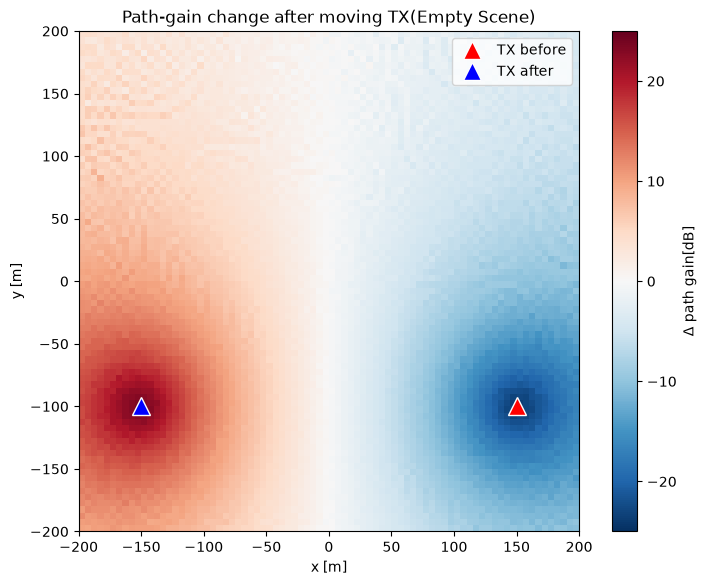

In [17]:
def To_db(p):
    out = np.full(p.shape, np.nan, dtype=np.float64)    #create an array whose shape is the same as p
    valid = p > 0       #make sure that the signal can reach the cell
    out[valid] = 10 * np.log10(p[valid])        #change the linear value into dB

    return out
                 
db_a = To_db(pg_a)
db_b = To_db(pg_b)

both = (pg_a > 0) & (pg_b > 0)          #Only calculated when there is signal (the cell is reachable)
delta = np.full(pg_a.shape, np.nan, dtype=np.float64)
delta[both] = db_b[both] - db_a[both]   #save the change of path gain before/after

extent = [-200, 200, -200, 200]

cmap = plt.colormaps["RdBu_r"].copy()   #red the path gain is stronger than before while blue is the opposite
cmap.set_bad("#222222")          # invalid cell is set to dark gray

dlim = 5 * np.ceil(np.nanpercentile(np.abs(delta), 99) / 5)  #the scale of the path gain change

fig, ax = plt.subplots(figsize=(8.5, 6.5))
im = ax.imshow(delta, origin="lower", extent=extent,
               cmap=cmap, vmin=-dlim, vmax=dlim)
fig.colorbar(im, ax=ax, label="Δ path gain[dB]")

ax.plot(POS_A[0], POS_A[1], "^", color="red", markersize=13,
        markeredgecolor="white", label="TX before")
ax.plot(POS_B[0], POS_B[1], "^", color="blue", markersize=13,
        markeredgecolor="white", label="TX after")

ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title("Path-gain change after moving TX(Empty Scene)")
ax.legend(loc="upper right")

plt.show()